# Imports

In [216]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [256]:
import xgboost as xgb

In [292]:
import optuna

/Users/teresitasanchezdecox/.pyenv/versions/3.13.15/envs/ExtraNoteBooks/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [265]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split

In [218]:
 # to be able to see the relationship between the missing values
from missingno import matrix

In [365]:
# importing my costum preprocessing class
from preprocessing_class import SpaceshipPreprocessor

# Data Exploration

In [301]:
df=pd.read_csv('train.csv')
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


## Looking at column data types

In [220]:
# looking at data type
df.dtypes

PassengerId         str
HomePlanet          str
CryoSleep        object
Cabin               str
Destination         str
Age             float64
VIP              object
RoomService     float64
FoodCourt       float64
ShoppingMall    float64
Spa             float64
VRDeck          float64
Name                str
Transported        bool
dtype: object

## Looking at the non-null counts for each column as well as their data type

In [302]:
# lets look at the non-null counts for each column as well as their data type
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 891.5+ KB


## We see there are some null values, how many exactly?

In [303]:
# we see there are some null values, how many exactly?
df.isnull().sum()

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Name            200
Transported       0
dtype: int64

In [304]:
rows_w_missingValues = df.isnull().any(axis=1).sum()
print(f'Total number of rows with at least one missing value: {rows_w_missingValues}')

Total number of rows with at least one missing value: 2087


## Summary Statistics for numeric columns

In [305]:
# Summary Statistics for numeric columns
df.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.000000,8512.000000,8510.000000,8485.000000,8510.000000,8505.000000
mean,28.827930,224.687617,458.077203,173.729169,311.138778,304.854791
std,14.489021,666.717663,1611.489240,604.696458,1136.705535,1145.717189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,47.000000,76.000000,27.000000,59.000000,46.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


# Defyning X and y for Baseline Model Prediction

In [ ]:
y = df['Transported']
y.head()

0    False
1     True
2    False
3    False
4     True
Name: Transported, dtype: bool

In [ ]:
X = df.drop(columns =['Transported'])
X.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines


# Looking at the relationship between the missing values

<Axes: >

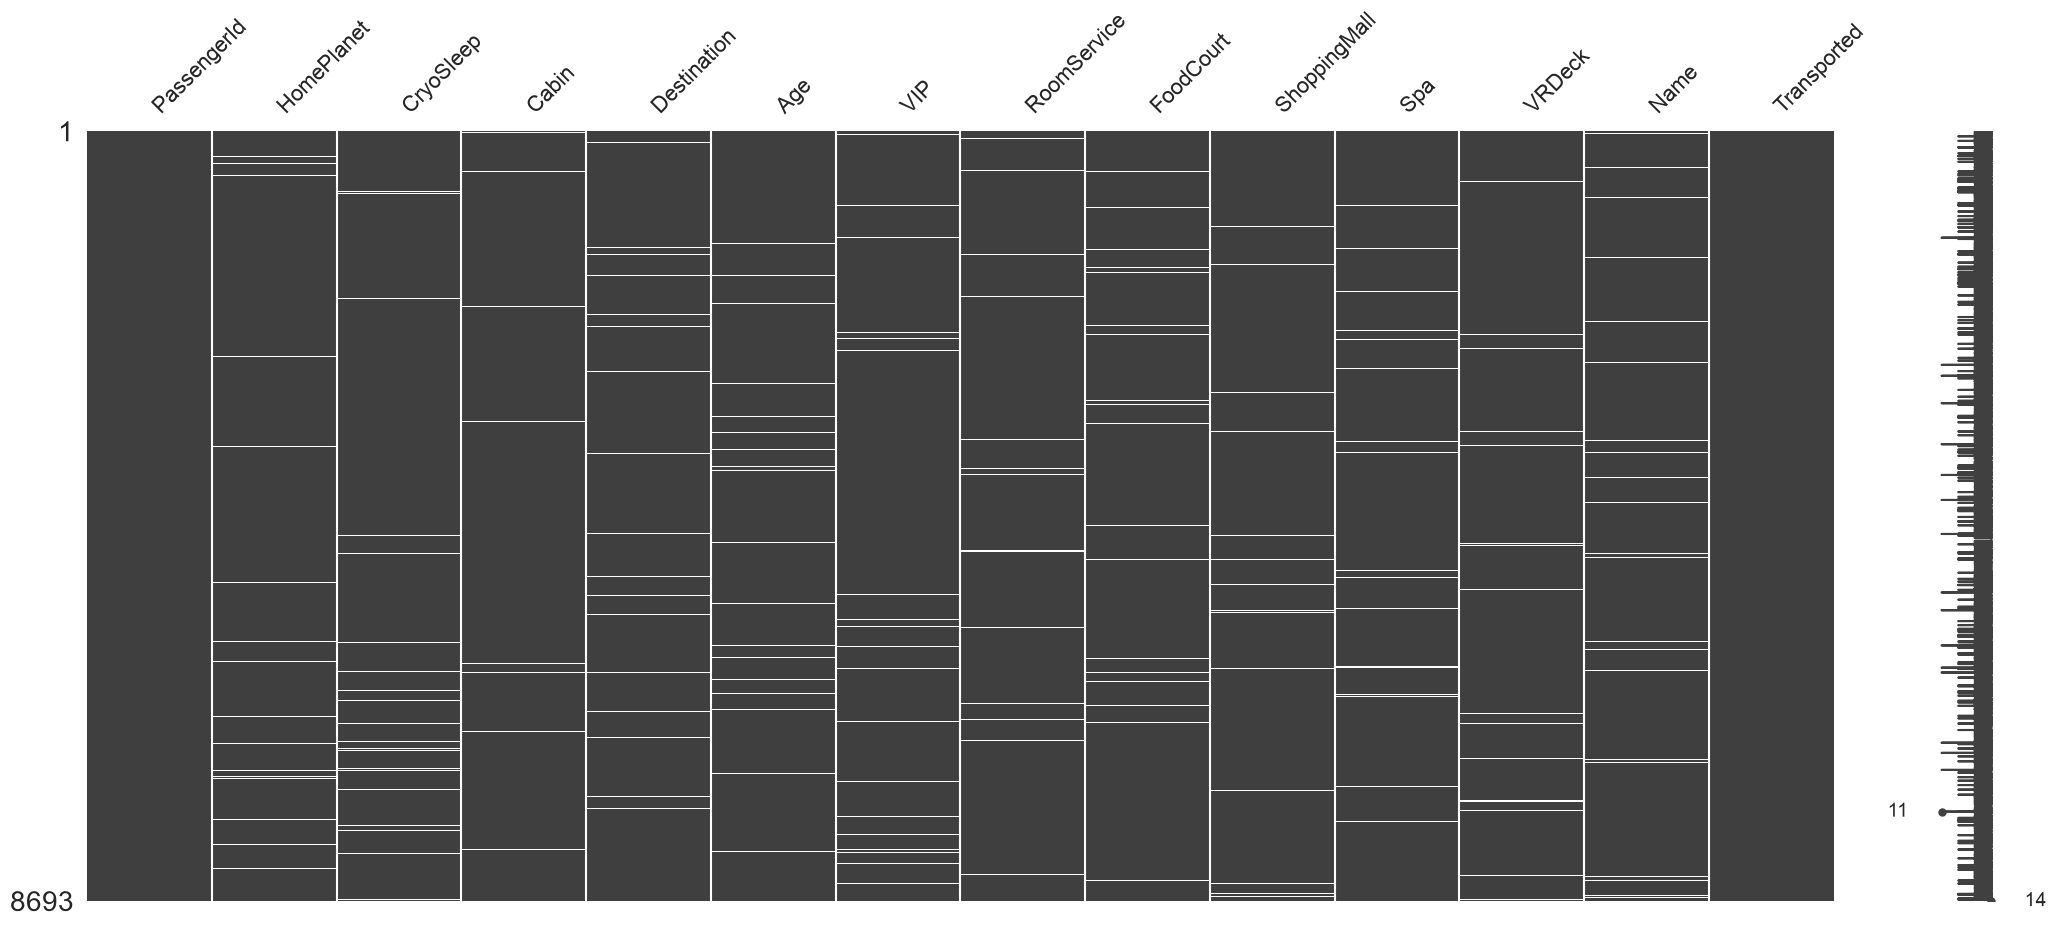

In [306]:
# looking at the relationship between the missing values
matrix(df)

# Baseline Model Prediction

## Getting rid of all missing values like a savage

In [ ]:
# Being that there is no obvious relationship between the different missing values,
# let's get rid of all of them like a savage just for the Baseline Model
df_dropedAllNAs=df.dropna()
df_dropedAllNAs.info()

<class 'pandas.DataFrame'>
Index: 6606 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   6606 non-null   str    
 1   HomePlanet    6606 non-null   str    
 2   CryoSleep     6606 non-null   object 
 3   Cabin         6606 non-null   str    
 4   Destination   6606 non-null   str    
 5   Age           6606 non-null   float64
 6   VIP           6606 non-null   object 
 7   RoomService   6606 non-null   float64
 8   FoodCourt     6606 non-null   float64
 9   ShoppingMall  6606 non-null   float64
 10  Spa           6606 non-null   float64
 11  VRDeck        6606 non-null   float64
 12  Name          6606 non-null   str    
 13  Transported   6606 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 729.0+ KB


## Declaring X and Y

In [ ]:
y = df_dropedAllNAs['Transported']
y.head()


0    False
1     True
2    False
3    False
4     True
Name: Transported, dtype: bool

In [ ]:
df_dropedAllNAs.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [ ]:
# using only numeric columns for X
Xnum = df_dropedAllNAs.select_dtypes(include=['number'])
Xnum

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
0,39.0,0.0,0.0,0.0,0.0,0.0
1,24.0,109.0,9.0,25.0,549.0,44.0
2,58.0,43.0,3576.0,0.0,6715.0,49.0
3,33.0,0.0,1283.0,371.0,3329.0,193.0
4,16.0,303.0,70.0,151.0,565.0,2.0
...,...,...,...,...,...,...
8688,41.0,0.0,6819.0,0.0,1643.0,74.0
8689,18.0,0.0,0.0,0.0,0.0,0.0
8690,26.0,0.0,0.0,1872.0,1.0,0.0
8691,32.0,0.0,1049.0,0.0,353.0,3235.0


In [ ]:
# Instantiate the logistic regression model
baseline_model=LogisticRegression()

# Train model on train data set
baseline_model.fit(Xnum,y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [ ]:
# Evaluate the model's performance
baseline_model.score(Xnum, y)

0.7797456857402362

# Thoughtful Feature Engineering

## The first part of the passanger ID indicates that people belong to a group. It is not unreasonable that people from the same group would share the same Cabin.

In [ ]:
# Extract the group ID from the passenger ID
df['Group'] = df['PassengerId'].apply(lambda x: x.split('_')[0])

# Forward fill or group-fill missing cabin data using group members
# If someone in group x has a cabin, give it to their traveling companions who are missing it.
df['Cabin'] = df.groupby('Group')['Cabin'].bfill().ffill()

In [308]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8693 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
 14  Group         8693 non-null   str    
dtypes: bool(1), float64(6), object(2), str(6)
memory usage: 959.4+ KB


In [309]:
rows_w_missingValues = df.isnull().any(axis=1).sum()
print(f'Total number of rows with at least one missing value: {rows_w_missingValues}')

Total number of rows with at least one missing value: 1929


## It seems quite reasonable that people staying in the same cabin, would have made the same choices regarding CryoSleep and VIP status, and would most likely be coming and going from and to the same place

In [310]:
# List of categories to check and impute based on cabin
cabin_categories = ['CryoSleep', 'VIP', 'HomePlanet', 'Destination']

for col in cabin_categories:
    print (f'Processing column by Cabin: {col}')

    # making sure to target only cabins that exist
    valid_cabin = df['Cabin'].notna()

    # calculate how many unique non-null values exist in each cabin
    ## transform()calculates a summary value for each group and broadcasts it back to match the original df's shape
    cabin_nunique = df[valid_cabin].groupby('Cabin')[col].transform(lambda x: x.nunique(dropna=True))

    # find cabins where all members have ONE value for a given category and at least one member without that category
    uniform_cabin = valid_cabin & (cabin_nunique ==1) & df[col].isna()

    # grab the shared value in a given cabin
    shared_cabin_values = df[valid_cabin].groupby('Cabin')[col].transform(lambda x:x.iloc[0] if x.notna().any() else None)

    # fill mising values for the cabin members without one
    df.loc[uniform_cabin, col] = shared_cabin_values[uniform_cabin]

    print (f'Filled missing values for uniform cabins in {col}')

Processing column by Cabin: CryoSleep
Filled missing values for uniform cabins in CryoSleep
Processing column by Cabin: VIP
Filled missing values for uniform cabins in VIP
Processing column by Cabin: HomePlanet
Filled missing values for uniform cabins in HomePlanet
Processing column by Cabin: Destination
Filled missing values for uniform cabins in Destination


In [311]:
df.info() # so not many missing values taken care this way

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8541 non-null   str    
 2   CryoSleep     8504 non-null   object 
 3   Cabin         8693 non-null   str    
 4   Destination   8532 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8537 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
 14  Group         8693 non-null   str    
dtypes: bool(1), float64(6), object(2), str(6)
memory usage: 959.4+ KB


## Handling the missing values resulting from CryoSleep

In [312]:
# For Preprocessing Pipeline
# List of columns that represent charges due to different ameneties in the cruise
# (which one cannot use if sleeping)
awake_amenity_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

# Updating the missin values of these columns to 0 if the passanger is in cryosleep
df.loc[df['CryoSleep']==True, awake_amenity_cols] = df.loc[df['CryoSleep']==True, awake_amenity_cols].fillna(0)


In [313]:
df.info() # so not many missing values taken care this way

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8541 non-null   str    
 2   CryoSleep     8504 non-null   object 
 3   Cabin         8693 non-null   str    
 4   Destination   8532 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8537 non-null   object 
 7   RoomService   8580 non-null   float64
 8   FoodCourt     8580 non-null   float64
 9   ShoppingMall  8581 non-null   float64
 10  Spa           8575 non-null   float64
 11  VRDeck        8568 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
 14  Group         8693 non-null   str    
dtypes: bool(1), float64(6), object(2), str(6)
memory usage: 959.4+ KB


In [314]:
rows_w_missingValues = df.isnull().any(axis=1).sum()
print(f'Total number of rows with at least one missing value: {rows_w_missingValues}')

Total number of rows with at least one missing value: 1484


## Assuming families will have similar behaviors, lets deal with names next

### Dealing with missing Names first

#### Let's first create a column indicating whether a name was missing

In [315]:
df['HadName']=df['Name'].notna().astype(int)
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,Group,HadName
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,0001,1
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True,0002,1
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,0003,1
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False,0003,1
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True,0004,1


#### Now let's fill missing names with unknown

In [316]:
df['Name']=df['Name'].fillna('Unknown')

#### Let's asume that people staying in the same cabin are from the same family: 

In [320]:
# Let's first make a last name column to make our lives easier
df['LastName']=df['Name'].str.split().str[-1]

# for each cabin, let's see if they have at least one last name other than unknown
def get_cabin_lastname(group):
    # Filter out 'Unknown' and NaNs to find a real family name in the cabin
    valid_names = group[group != 'Unknown'].dropna()
    if not valid_names.empty:
        return valid_names.iloc[0] # Return the first real last name found
    return 'Unknown'

# Calculate the dominant last name per cabin
cabin_family_name = df[valid_cabin].groupby('Cabin')['LastName'].transform(get_cabin_lastname)

# Fill missing/Unknown names where the cabin shares a known family name
name_impute = valid_cabin & (df['LastName'] == 'Unknown') & (cabin_family_name != 'Unknown')

# Let's update the LastName column with the Cabin Name
df.loc[name_impute, 'LastName'] = cabin_family_name[name_impute]

In [321]:
# Count total passengers with a last name other than unknown
known_family_passengers = df.loc[(df['LastName'].notna()) & (df['LastName'] != 'Unknown')].shape[0]

print(f"Number of passengers belonging to a known family: {known_family_passengers}")

Number of passengers belonging to a known family: 8574


In [322]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8541 non-null   str    
 2   CryoSleep     8504 non-null   object 
 3   Cabin         8693 non-null   str    
 4   Destination   8532 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8537 non-null   object 
 7   RoomService   8580 non-null   float64
 8   FoodCourt     8580 non-null   float64
 9   ShoppingMall  8581 non-null   float64
 10  Spa           8575 non-null   float64
 11  VRDeck        8568 non-null   float64
 12  Name          8693 non-null   str    
 13  Transported   8693 non-null   bool   
 14  Group         8693 non-null   str    
 15  HadName       8693 non-null   int64  
 16  LastName      8693 non-null   object 
dtypes: bool(1), float64(6), int64(1), object(3), str(6)
memory usage: 1.1+ MB


#### Let's look at the relationship between the remaining missing values

<Axes: >

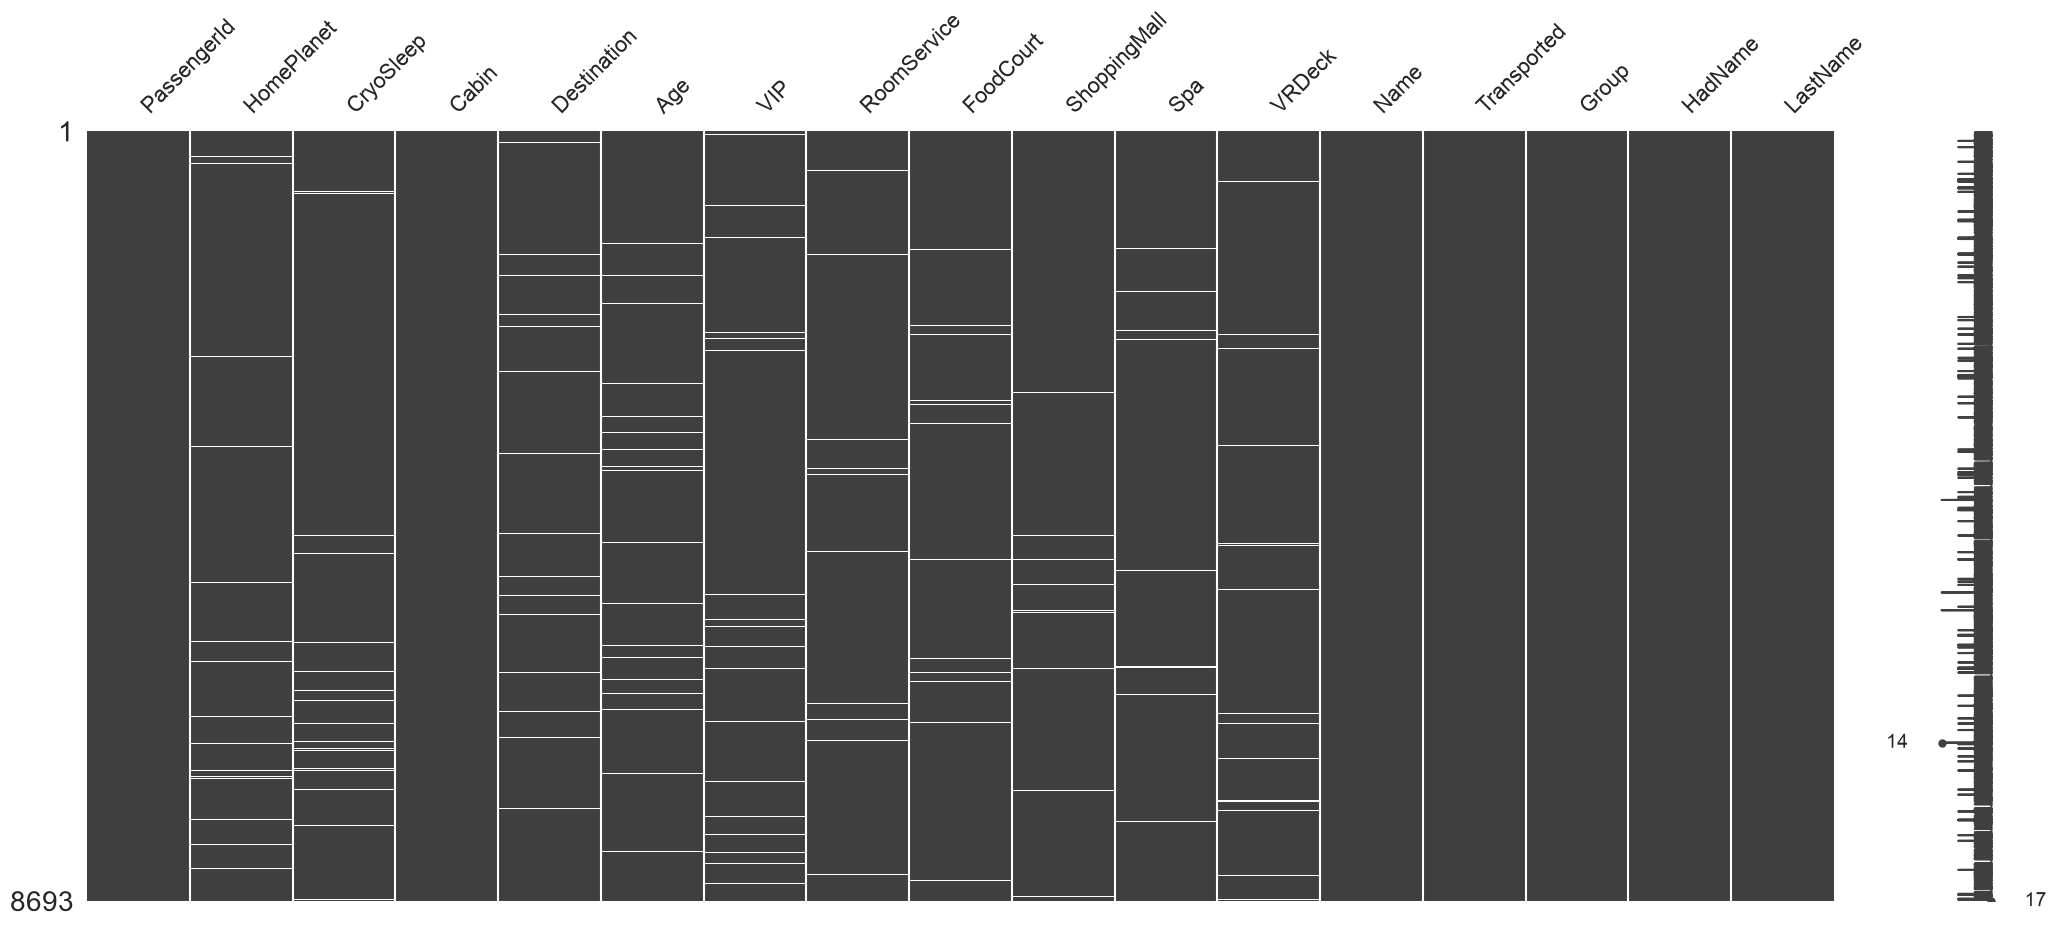

In [323]:
# looking at the relationship between the missing values
matrix(df)

#### Do we have still cabins without a proper last name?

In [324]:
# Check if any cabin contains a MIX of a valid last name AND 'Unknown' after your imputation step
mixed_cabins = df[df['Cabin'].notna()].groupby('Cabin')['LastName'].apply(
    lambda names: (names != 'Unknown').any() and (names == 'Unknown').any()
)

print(f"Cabins with a mix of valid names and 'Unknown' left: {mixed_cabins.sum()}")

Cabins with a mix of valid names and 'Unknown' left: 0


#### Let's see how many rows with missing values we have left

In [325]:
rows_w_missingValues = df.isnull().any(axis=1).sum()
print(f'Total number of rows with at least one missing value: {rows_w_missingValues}')

Total number of rows with at least one missing value: 1315


### Now let's work with families as a unit

#### Let's see how many different last names there are.

In [326]:
names_lastnames = df['Name'].str.split()
lastnames = names_lastnames.str[-1]
unique_lastnames_count = lastnames.nunique()

print (f'Number of unique last names; {unique_lastnames_count}')

Number of unique last names; 2218


#### Let's see how many family members are traveling toghether


In [327]:
# Calculate the family_sizes
family_sizes= lastnames.value_counts()
family_sizes.head()

Name
Unknown      200
Casonston     18
Oneiles       16
Litthews      15
Domington     15
Name: count, dtype: int64

In [328]:
# Distribution of family sizes: to see if the family sizes that we got are reasonable
distribution = family_sizes.value_counts().sort_index()
distribution.head()

count
1    382
2    400
3    388
4    320
5    256
Name: count, dtype: int64

/var/folders/mc/j4mj5rgd42717rg3bzzylk1w0000gn/T/ipykernel_26624/1460325788.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=x_vals, y=y_vals, palette="Blues_d")


Text(0, 0.5, 'Number of Families')

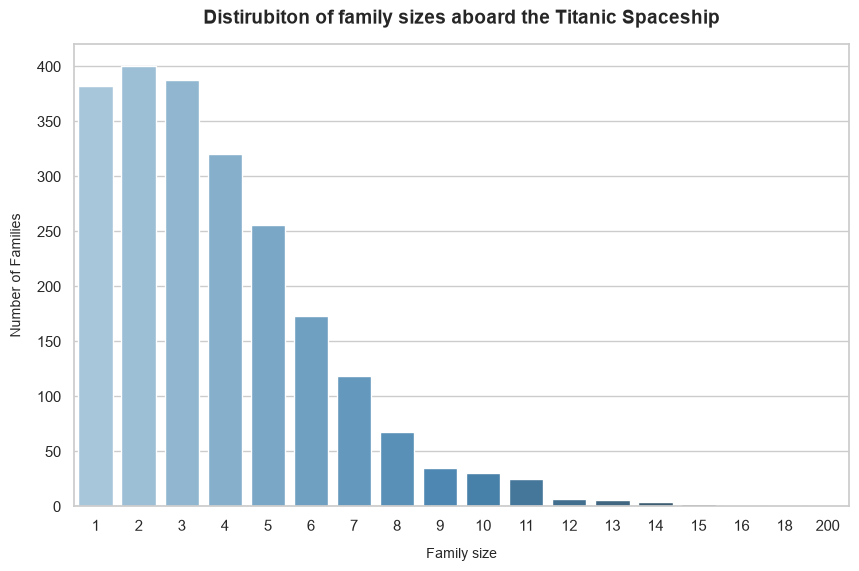

In [329]:
# Converting the indexes explicitly into integers as I got an error involving dtypes
x_vals = distribution.index.astype(int)
y_vals = distribution.values

# The bar chart
## settign the sns theme
sns.set_theme (style = "whitegrid")
## creating the plot space
plt.figure (figsize = (10, 6))
## declaring the axis
ax = sns.barplot(x=x_vals, y=y_vals, palette="Blues_d")
## titles and laberls
plt.title('Distirubiton of family sizes aboard the Titanic Spaceship', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Family size', fontsize=10, labelpad=10)
plt.ylabel('Number of Families', fontsize=10, labelpad=10)

#### The vast majority of the family sizes seem quite reasonable, so I will continue with my line of thinking.

### It is reasonable to asume that families are coming and going from and to the same planets, that they would have the same decision regarding cryosleeping and VIP treatment and that their cabins would be next to each other. 

### Let's takle the simplest scenario first: 
1. Check for the last names that have missing homeplanets, destinations, cryosleep or VIP status
2. For each of those missing values, check if the family members that do have a value for that category, have the same value 
3. Dealing with missing values:
3a. If everyone in the family has the same value for a given category, fill the missing value of the family members having a missing value with the aforementioned value.
3b. Let's make a list of the lastnames that have different values for a given category 

In [330]:
features_to_check = ['HomePlanet', 'Destination', 'CryoSleep', 'VIP']

# Stablish a maximum family size as not to group all the unknowns into one family
MAX_FAMILY_SIZE = 20 # yes, the family of my syster-in-law goes ones a year in a cruise, they are 36!

for col in features_to_check:
    print(f"\n--- Processing column by Family: {col} ---")

    # Looking only for reasonably sized families with a valid last name
    valid_family_mask = (
        df['LastName'].notna() &
        (df['LastName'] != 'Unknown') &
        df['LastName'].map(lambda x: family_sizes.get(x, 0) <= MAX_FAMILY_SIZE)
    )

    # Check how many unique non-null values exist for each family group
    family_nunique = df[valid_family_mask].groupby('LastName')[col].transform(lambda x: x.nunique(dropna=True))

    # Impute: Family has uniform data (nunique == 1) AND the passenger is missing this value
    uniform_families_mask = valid_family_mask & (family_nunique == 1) & df[col].isna()

    # Grab the shared value for each family group safely
    shared_family_values = df[valid_family_mask].groupby('LastName')[col].transform(
        lambda x: x.iloc[0] if x.notna().any() else None
    )

    # Fill the missing values
    df.loc[uniform_families_mask, col] = shared_family_values[uniform_families_mask]
    print(f"Filled missing values for uniform families in {col}.")



--- Processing column by Family: HomePlanet ---
Filled missing values for uniform families in HomePlanet.

--- Processing column by Family: Destination ---
Filled missing values for uniform families in Destination.

--- Processing column by Family: CryoSleep ---
Filled missing values for uniform families in CryoSleep.

--- Processing column by Family: VIP ---
Filled missing values for uniform families in VIP.


In [331]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8653 non-null   str    
 2   CryoSleep     8540 non-null   object 
 3   Cabin         8693 non-null   str    
 4   Destination   8566 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8630 non-null   object 
 7   RoomService   8580 non-null   float64
 8   FoodCourt     8580 non-null   float64
 9   ShoppingMall  8581 non-null   float64
 10  Spa           8575 non-null   float64
 11  VRDeck        8568 non-null   float64
 12  Name          8693 non-null   str    
 13  Transported   8693 non-null   bool   
 14  Group         8693 non-null   str    
 15  HadName       8693 non-null   int64  
 16  LastName      8693 non-null   object 
dtypes: bool(1), float64(6), int64(1), object(3), str(6)
memory usage: 1.1+ MB


In [332]:
rows_w_missingValues = df.isnull().any(axis=1).sum()
print(f'Total number of rows with at least one missing value: {rows_w_missingValues}')

Total number of rows with at least one missing value: 1069


In [333]:
# Tracking the families with different values for ['HomePlanet', 'Destination', 'CryoSleep', 'VIP']
conflicting_families = {}
valid_df = df[valid_family_mask]

for col in features_to_check:
    # Track conflicting families: families where valid members have more than 1 distinct value
    grouped = valid_df.groupby('LastName')[col]
    multi_val_mask = grouped.transform(lambda x: x.dropna().nunique() > 1)
    conflicting_families[col] = valid_df.loc[multi_val_mask, 'LastName'].unique().tolist()

    print(f"Number of valid families with conflicting {col} values: {len(conflicting_families[col])}")

# Optional: View conflicting last names for a specific column, e.g., CryoSleep
# print("Conflicting families for CryoSleep:", conflicting_families['CryoSleep'])

Number of valid families with conflicting HomePlanet values: 1
Number of valid families with conflicting Destination values: 1224
Number of valid families with conflicting CryoSleep values: 1355
Number of valid families with conflicting VIP values: 169


In [334]:
conflicting_families['CryoSleep']

['Susent',
 'Santantines',
 'Jacostaffey',
 'Beston',
 'Flatic',
 'Barne',
 'Baketton',
 'Bertsontry',
 'Pooles',
 'Hughriend',
 'Upead',
 'Brighttt',
 'Brantuarez',
 'Mcfaddennon',
 'Mare',
 'Datie',
 'Butte',
 'Wheelez',
 'Moodsey',
 'Coopelandez',
 'Chmad',
 'Johnshines',
 'Hubbarton',
 'Tractive',
 'Ayalazquez',
 'Greeves',
 'Leeves',
 'Binie',
 'Dillines',
 'Make',
 'Mostedry',
 'Dal',
 'Vinozarks',
 'Datte',
 'Coopezmaney',
 'Ellcefulve',
 'Sacre',
 'Santry',
 'Yorkland',
 'Hewson',
 'Fictful',
 'Carezquez',
 'Leetersoney',
 'Trad',
 'Holson',
 'Mclainez',
 'Cleachrand',
 'Handertiz',
 'Aloubtled',
 'Supred',
 'Cowtale',
 'Carvis',
 'Pead',
 'Suptive',
 'Coning',
 'Hayder',
 'Fielson',
 'Mesty',
 'Fowles',
 'Blie',
 'Harmontry',
 'Gambs',
 'Myling',
 'Mejiaddox',
 'Whitakers',
 'Dayers',
 'Wolferguson',
 'Hubbarrison',
 'Simson',
 'Estron',
 'Hetforhaft',
 'Hutchinton',
 'Anche',
 'Floaf',
 'Mcmahoney',
 'Gordanieves',
 'Grifford',
 'Lambles',
 'Knik',
 'Webstephrey',
 'Disight',

### It seems reasonable that the missing data for children's expenses during the cruise would be 0 as their parents would have paid for it

In [335]:
# Define spending columns
spending_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

child_age_threshold = 18

# Apply 0 specifically to missing spending values for children
child_missing_spending_mask = (df['Age'] <= child_age_threshold) & df[spending_cols].isna().any(axis=1)

for col in spending_cols:
    # Fill missing spending with 0 where the passenger is a child
    child_mask = (df['Age'] <= child_age_threshold) & df[col].isna()
    df.loc[child_mask, col] = 0

print(f"Filled missing spending columns with 0 for children (Age <= {child_age_threshold}).")


Filled missing spending columns with 0 for children (Age <= 18).


In [336]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8653 non-null   str    
 2   CryoSleep     8540 non-null   object 
 3   Cabin         8693 non-null   str    
 4   Destination   8566 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8630 non-null   object 
 7   RoomService   8600 non-null   float64
 8   FoodCourt     8598 non-null   float64
 9   ShoppingMall  8595 non-null   float64
 10  Spa           8594 non-null   float64
 11  VRDeck        8601 non-null   float64
 12  Name          8693 non-null   str    
 13  Transported   8693 non-null   bool   
 14  Group         8693 non-null   str    
 15  HadName       8693 non-null   int64  
 16  LastName      8693 non-null   object 
dtypes: bool(1), float64(6), int64(1), object(3), str(6)
memory usage: 1.1+ MB


<Axes: >

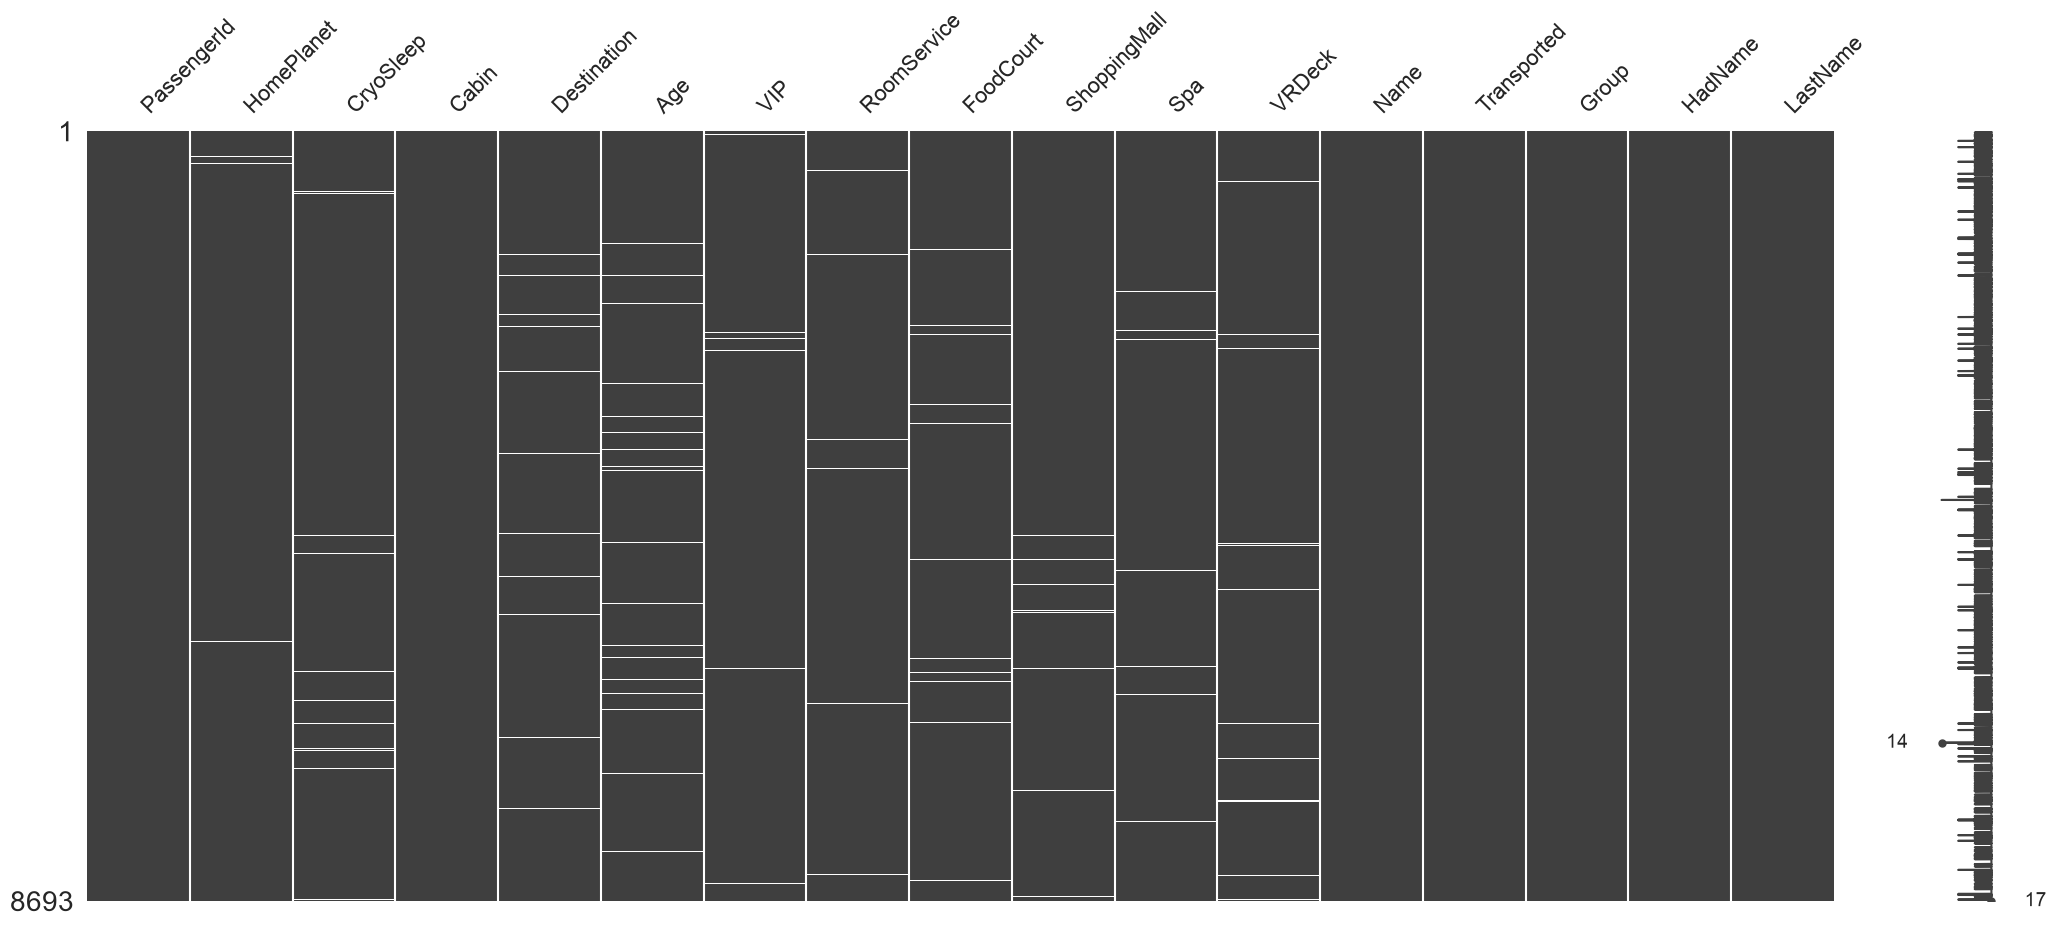

In [337]:
# looking at the relationship between the missing values
matrix(df)

In [338]:
rows_w_missingValues = df.isnull().any(axis=1).sum()
print(f'Total number of rows with at least one missing value: {rows_w_missingValues}')

Total number of rows with at least one missing value: 975


## Let's assume the 'missing' expenses incurred in the cruise are 'missing' because there were no expenses incurred

In [339]:
spending_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

# Fill missing spending values with 0
df[spending_cols] = df[spending_cols].fillna(0)

# Verify remaining missing values in spending columns
print("Remaining missing values in spending columns:")
print(df[spending_cols].isna().sum())

Remaining missing values in spending columns:
RoomService     0
FoodCourt       0
ShoppingMall    0
Spa             0
VRDeck          0
dtype: int64


In [340]:
rows_w_missingValues = df.isnull().any(axis=1).sum()
print(f'Total number of rows with at least one missing value: {rows_w_missingValues}')

Total number of rows with at least one missing value: 549


## Let's look closer to the distribution of the cabins the titanic

In [341]:
# Parse the Cabin column into Deck, Num, and Side
## Fill temporary placeholders for missing cabins before splitting
#df['Cabin'] = df['Cabin'].fillna('Unknown/0/U')
#df[['Deck', 'Num', 'Side']] = df['Cabin'].str.split('/', expand=True)
#df['Num'] = pd.to_numeric(df['Num'], errors='coerce').fillna(-1).astype(int)

# Parse the Cabin column WITHOUT filling missing strings first.
# Rows where 'Cabin' is NaN will result in NaN for Deck, Num, and Side
##### We want to be able to explode XGBoost's ability to handle NaNs
cabin_split = df['Cabin'].str.split('/', expand=True)
if cabin_split.shape[1] == 3:
    df['Deck'] = cabin_split[0]
    df['Num'] = pd.to_numeric(cabin_split[1], errors='coerce')
    df['Side'] = cabin_split[2]
else:
    # Fallback safety if any malformed rows exist
    df['Deck'] = pd.Series(dtype='object')
    df['Num'] = pd.Series(dtype='float')
    df['Side'] = pd.Series(dtype='object')

In [343]:
df.head(5)

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,Group,HadName,LastName,Deck,Num,Side
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,0001,1,Ofracculy,B,0,P
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True,0002,1,Vines,F,0,S
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,0003,1,Susent,A,0,S
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False,0003,1,Susent,A,0,S
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True,0004,1,Santantines,F,1,S


In [344]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 20 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8653 non-null   str    
 2   CryoSleep     8540 non-null   object 
 3   Cabin         8693 non-null   str    
 4   Destination   8566 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8630 non-null   object 
 7   RoomService   8693 non-null   float64
 8   FoodCourt     8693 non-null   float64
 9   ShoppingMall  8693 non-null   float64
 10  Spa           8693 non-null   float64
 11  VRDeck        8693 non-null   float64
 12  Name          8693 non-null   str    
 13  Transported   8693 non-null   bool   
 14  Group         8693 non-null   str    
 15  HadName       8693 non-null   int64  
 16  LastName      8693 non-null   object 
 17  Deck          8693 non-null   str    
 18  Num           8693 non-null   int64  
 

# Preparing X and Y for XG Boost Model

## Getting rid of redundant variables: Cabin (Split it into its components) and Passanger ID (got the group portion from it) and Name (got the last names out of it)

In [345]:
drop_cols= ['Cabin', 'PassengerId', 'Name', 'Transported']
X = df.drop(columns=[col for col in drop_cols if col in df.columns])
y = df['Transported']

## Casting categorical features as XGBoost's categorical handler natively preserves and evaluates NaN

In [346]:
categorical_cols = ['HomePlanet', 'Destination', 'Deck', 'Side', 'LastName']
for col in categorical_cols:
    if col in X.columns:
        X[col] = X[col].astype('category')

## Casting boolean features letting XGBoost evaluate them using its sparsity-aware numerical split finder

In [347]:
bool_cols = ['CryoSleep', 'VIP']
for col in bool_cols:
    if col in X.columns:
        X[col] = X[col].astype('boolean')

In [348]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   HomePlanet    8653 non-null   category
 1   CryoSleep     8540 non-null   boolean 
 2   Destination   8566 non-null   category
 3   Age           8514 non-null   float64 
 4   VIP           8630 non-null   boolean 
 5   RoomService   8693 non-null   float64 
 6   FoodCourt     8693 non-null   float64 
 7   ShoppingMall  8693 non-null   float64 
 8   Spa           8693 non-null   float64 
 9   VRDeck        8693 non-null   float64 
 10  Group         8693 non-null   str     
 11  HadName       8693 non-null   int64   
 12  LastName      8693 non-null   category
 13  Deck          8693 non-null   category
 14  Num           8693 non-null   int64   
 15  Side          8693 non-null   category
dtypes: boolean(2), category(5), float64(6), int64(2), str(1)
memory usage: 713.7 KB


In [349]:
df['Group'] = df['Group'].astype(int)
X['Group'] = X['Group'].astype(int)

In [350]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   HomePlanet    8653 non-null   category
 1   CryoSleep     8540 non-null   boolean 
 2   Destination   8566 non-null   category
 3   Age           8514 non-null   float64 
 4   VIP           8630 non-null   boolean 
 5   RoomService   8693 non-null   float64 
 6   FoodCourt     8693 non-null   float64 
 7   ShoppingMall  8693 non-null   float64 
 8   Spa           8693 non-null   float64 
 9   VRDeck        8693 non-null   float64 
 10  Group         8693 non-null   int64   
 11  HadName       8693 non-null   int64   
 12  LastName      8693 non-null   category
 13  Deck          8693 non-null   category
 14  Num           8693 non-null   int64   
 15  Side          8693 non-null   category
dtypes: boolean(2), category(5), float64(6), int64(3)
memory usage: 713.7 KB


# XG Boost Model leaving 549 missing values

## Train / Validation Split: stratified to ensure class balance

In [351]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Initialize and Train XG Boost Classifier

In [ ]:
# Defining our XG Boost Classifier
clf = xgb.XGBClassifier(
    n_estimators=150,
    learning_rate=0.08,
    max_depth=5,
    enable_categorical=True,
    random_state=42,
    eval_metric='logloss'
)

clf.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


## Evaluate Performance

In [353]:
y_pred = clf.predict(X_val)
accuracy = accuracy_score(y_val, y_pred)

print(f"Validation Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_val, y_pred))

Validation Accuracy: 0.7729

Classification Report:
              precision    recall  f1-score   support

       False       0.76      0.79      0.77       863
        True       0.78      0.76      0.77       876

    accuracy                           0.77      1739
   macro avg       0.77      0.77      0.77      1739
weighted avg       0.77      0.77      0.77      1739



# Cross Validation and HyperParameter Tunning

## Convert processed X and y into XGBoost's DMatrix format

In [354]:
dtrain = xgb.DMatrix(X, label=y, enable_categorical=True)

## Define the function that Optuna will optimize:
### - Hyperparamenters to test within specified ranges
### - 5-fold Cross-Validation
### - Extract the best evaluation score

n_estimators=150 & learning_rate=0.08: A lower learning rate (like 0.05 to 0.1) combined with a moderate number of trees ensures that each tree learns slowly and builds on the residuals of the previous ones. This generally yields better generalization than a high learning rate with fewer trees.

max_depth=5: Setting the maximum depth of each tree to 5 prevents the trees from growing too complex. For tabular data with moderate feature counts, keeping depth between 4 and 6 helps prevent memorizing noise in the training set.

enable_categorical=True: This is essential for letting XGBoost natively handle the category dtype columns (Deck, Side, LastName, etc.) using its internal partitioning algorithm rather than forcing manual one-hot encoding.

eval_metric='logloss': Since this is a binary classification problem (Transported: True/False), logistic loss (logloss) is the standard metric to track probability errors during training.

In [355]:
def objective(trial):
    # Suggest hyperparameters to test within specified ranges
    params = {
        'objective': 'binary:logistic',
        'eval_metric': 'logloss',
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 9),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma': trial.suggest_float('gamma', 0.0, 5.0),
        'random_state': 42,
        'tree_method': 'hist' # Fast histogram-optimized splitting
    }

    # Run 5-fold cross-validation using xgb.cv
    cv_results = xgb.cv(
        params,
        dtrain,
        num_boost_round=500,
        nfold=5,
        stratified=True,
        early_stopping_rounds=30,
        verbose_eval=False
    )

    # Extract the best evaluation score (minimum logloss on validation folds)
    best_logloss = cv_results['test-logloss-mean'].min()

    return best_logloss

## Create the study and run the optimization:
### - logloss is an error metric, as such, we want to 'minimize' it

In [356]:
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=30, timeout=600) # Runs 30 trials or stops after 10 mins

[I 2026-10-15 09:25:34,698] A new study created in memory with name: no-name-e22e27b7-a2bb-4e1a-8bde-152691402e88
[I 2026-10-15 09:25:37,003] Trial 0 finished with value: 0.5129917334473287 and parameters: {'learning_rate': 0.02178288123017584, 'max_depth': 9, 'min_child_weight': 9, 'subsample': 0.9608939098882632, 'colsample_bytree': 0.8612558030391173, 'gamma': 4.404785004799788}. Best is trial 0 with value: 0.5129917334473287.
[I 2026-10-15 09:25:37,919] Trial 1 finished with value: 0.5177563859315899 and parameters: {'learning_rate': 0.07707718464839347, 'max_depth': 4, 'min_child_weight': 7, 'subsample': 0.747656125571738, 'colsample_bytree': 0.9832391323288221, 'gamma': 2.4648726806400125}. Best is trial 0 with value: 0.5129917334473287.
[I 2026-10-15 09:25:42,218] Trial 2 finished with value: 0.494308668696573 and parameters: {'learning_rate': 0.010456398465379203, 'max_depth': 9, 'min_child_weight': 9, 'subsample': 0.9691268137444398, 'colsample_bytree': 0.7413119560339471, 'ga

## Print the best results

In [357]:
print("Best Hyperparameters Found:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

print(f"\nBest Cross-Validation LogLoss: {study.best_value:.4f}")

Best Hyperparameters Found:
  learning_rate: 0.02722012382202059
  max_depth: 6
  min_child_weight: 7
  subsample: 0.6812559910647636
  colsample_bytree: 0.6059496387116078
  gamma: 2.5102275087235264

Best Cross-Validation LogLoss: 0.4688


# Train Final XG Boost Model (still with the 549 missing values) with the best hyperparameters found by Optuna 

## Let's train the model on ALL of our data with the super hyperparamenters

## Let's extract the best parameters from the Opotuna study

In [358]:
# Extract the best parameters from Optuna study
best_params = study.best_params

## Add back static parameters (objective, evaluation metric, tree method, etc.)

In [300]:
final_params = {
    'objective': 'binary:logistic',
    'eval_metric': 'logloss',
    'tree_method': 'hist',
    'random_state': 42,
    **best_params  # Unpacks all the optimized parameters found by Optuna
}

## Run cv one last time using the best Optuna parameters to find the optimal number of runs

In [359]:
# Run cv one last time using the best parameters found by Optuna
cv_results = xgb.cv(
    final_params,
    dtrain,
    num_boost_round=1000,
    nfold=5,
    stratified=True,
    early_stopping_rounds=30,
    verbose_eval=False
)

# The optimal number of trees is exactly how many rounds survived before early stopping
best_num_rounds = len(cv_results)
print(f"Optimal number of trees (boosting rounds): {best_num_rounds}")

Optimal number of trees (boosting rounds): 250


## Now we are ready to train our final model 

### Either using the XGBoost's native API (xgb.train), which returns an xgboost.core.Booster object: 
* The Booster is a raw C++ backend object, so it outputs a simple text line

In [360]:
final_model = xgb.train(final_params, dtrain, num_boost_round=best_num_rounds)

In [361]:
# Check what kind of object final_model is
print(type(final_model))

# Check how many trees it actually built
print(final_model.num_boosted_rounds())

<class 'xgboost.core.Booster'>
250


### or using the scikit-learn's API (specifically an XGBClassifier), which renders a nice interactive HTML widget in Jupyter Notebooks when you inspect a fitted model, as well as methods such as .predict() directly on pandas DataFrames without needing to wrap them in a DMatrix manually.

In [363]:
# Initialize the classifier using best parameters from Optuna
clf = xgb.XGBClassifier(
    **best_params,
    n_estimators=best_num_rounds,
    objective='binary:logistic',
    eval_metric='logloss',
    tree_method='hist',
    enable_categorical=True,
    random_state=42
)

# Fit on full training data
clf.fit(X, y)

clf

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.6059496387116078
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


## Evaluate Performance

In [364]:
y_pred = clf.predict(X_val)
accuracy = accuracy_score(y_val, y_pred)

print(f"Validation Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_val, y_pred))

Validation Accuracy: 0.9195

Classification Report:
              precision    recall  f1-score   support

       False       0.92      0.92      0.92       863
        True       0.92      0.92      0.92       876

    accuracy                           0.92      1739
   macro avg       0.92      0.92      0.92      1739
weighted avg       0.92      0.92      0.92      1739



# I combined all my costum preprocessing into a preprocessing class, let's fit the preprocessor on the training data so that it can then be applied to the test data

## Reloading the original train data

In [368]:
df=pd.read_csv('train.csv')
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


## Initialize and fit the preprocessor on training data

In [ ]:
# Initialize and fit the preprocessor on training data
preprocessor = SpaceshipPreprocessor(max_family_size=20)
preprocessor.fit(df.drop(columns=['Transported']))


,max_family_size,20


# Transforming (preprocessing) the training data

In [ ]:
X_train = preprocessor.transform(df)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [376]:
X_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   HomePlanet    8653 non-null   category
 1   CryoSleep     8540 non-null   boolean 
 2   Destination   8566 non-null   category
 3   Age           8514 non-null   float64 
 4   VIP           8630 non-null   boolean 
 5   RoomService   8693 non-null   float64 
 6   FoodCourt     8693 non-null   float64 
 7   ShoppingMall  8693 non-null   float64 
 8   Spa           8693 non-null   float64 
 9   VRDeck        8693 non-null   float64 
 10  Transported   8693 non-null   bool    
 11  Group         8693 non-null   int64   
 12  HadName       8693 non-null   int64   
 13  LastName      8693 non-null   category
 14  Deck          8693 non-null   category
 15  Num           8693 non-null   int64   
 16  Side          8693 non-null   category
dtypes: bool(1), boolean(2), category(5), float64(6), int64(3)
memor

## Loading Test Data

In [377]:
df_test=pd.read_csv('test.csv')
df_test.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name
0,0013_01,Earth,True,G/3/S,TRAPPIST-1e,27.0,False,0.0,0.0,0.0,0.0,0.0,Nelly Carsoning
1,0018_01,Earth,False,F/4/S,TRAPPIST-1e,19.0,False,0.0,9.0,0.0,2823.0,0.0,Lerome Peckers
2,0019_01,Europa,True,C/0/S,55 Cancri e,31.0,False,0.0,0.0,0.0,0.0,0.0,Sabih Unhearfus
3,0021_01,Europa,False,C/1/S,TRAPPIST-1e,38.0,False,0.0,6652.0,0.0,181.0,585.0,Meratz Caltilter
4,0023_01,Earth,False,F/5/S,TRAPPIST-1e,20.0,False,10.0,0.0,635.0,0.0,0.0,Brence Harperez


## Transforming (preprocessing) the test data

In [378]:
df_test = preprocessor.transform(df_test)
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 4277 entries, 0 to 4276
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   HomePlanet    4241 non-null   category
 1   CryoSleep     4216 non-null   boolean 
 2   Destination   4223 non-null   category
 3   Age           4186 non-null   float64 
 4   VIP           4236 non-null   boolean 
 5   RoomService   4277 non-null   float64 
 6   FoodCourt     4277 non-null   float64 
 7   ShoppingMall  4277 non-null   float64 
 8   Spa           4277 non-null   float64 
 9   VRDeck        4277 non-null   float64 
 10  Group         4277 non-null   int64   
 11  HadName       4277 non-null   int64   
 12  LastName      4277 non-null   category
 13  Deck          4277 non-null   category
 14  Num           4277 non-null   int64   
 15  Side          4277 non-null   category
dtypes: boolean(2), category(5), float64(6), int64(3)
memory usage: 356.2 KB


# Generating predictions for submission 

In [380]:
y_pred = clf.predict(df_test)

XGBoostError: [10:49:49] /Users/runner/work/xgboost/xgboost/src/data/cat_container.h:29: Found a category not in the training set for the 12th (0-based) column: `Aginoid`
Stack trace:
  [bt] (0) 1   libxgboost.dylib                    0x00000001226416d0 dmlc::LogMessageFatal::~LogMessageFatal() + 124
  [bt] (1) 2   libxgboost.dylib                    0x00000001227bbcd8 xgboost::EncErrorPolicy::Error(std::__1::basic_string<char, std::__1::char_traits<char>, std::__1::allocator<char>>&&) const + 88
  [bt] (2) 3   libxgboost.dylib                    0x00000001228273c8 void enc::detail::ReportMissing<enc::Policy<xgboost::EncErrorPolicy>>(enc::Policy<xgboost::EncErrorPolicy> const&, std::__1::basic_string<char, std::__1::char_traits<char>, std::__1::allocator<char>> const&, unsigned long) + 168
  [bt] (3) 4   libxgboost.dylib                    0x00000001228270e4 void enc::Recode<enc::Policy<xgboost::EncErrorPolicy>>(enc::Policy<xgboost::EncErrorPolicy> const&, enc::detail::ColumnsViewImpl<std::__1::variant<enc::CatStrArrayView, xgboost::common::Span<unsigned char const, 18446744073709551615ul>, xgboost::common::Span<signed char const, 18446744073709551615ul>, xgboost::common::Span<unsigned short const, 18446744073709551615ul>, xgboost::common::Span<short const, 18446744073709551615ul>, xgboost::common::Span<unsigned int const, 18446744073709551615ul>, xgboost::common::Span<int const, 18446744073709551615ul>, xgboost::common::Span<unsigned long long const, 18446744073709551615ul>, xgboost::common::Span<long long const, 18446744073709551615ul>>>, xgboost::common::Span<int const, 18446744073709551615ul>, enc::detail::ColumnsViewImpl<std::__1::variant<enc::CatStrArrayView, xgboost::common::Span<unsigned char const, 18446744073709551615ul>, xgboost::common::Span<signed char const, 18446744073709551615ul>, xgboost::common::Span<unsigned short const, 18446744073709551615ul>, xgboost::common::Span<short const, 18446744073709551615ul>, xgboost::common::Span<unsigned int const, 18446744073709551615ul>, xgboost::common::Span<int const, 18446744073709551615ul>, xgboost::common::Span<unsigned long long const, 18446744073709551615ul>, xgboost::common::Span<long long const, 18446744073709551615ul>>>, xgboost::common::Span<int, 18446744073709551615ul>)::'lambda'(enc::CatStrArrayView const&)::operator()(enc::CatStrArrayView const&) const + 452
  [bt] (4) 5   libxgboost.dylib                    0x0000000122826898 void enc::Recode<enc::Policy<xgboost::EncErrorPolicy>>(enc::Policy<xgboost::EncErrorPolicy> const&, enc::detail::ColumnsViewImpl<std::__1::variant<enc::CatStrArrayView, xgboost::common::Span<unsigned char const, 18446744073709551615ul>, xgboost::common::Span<signed char const, 18446744073709551615ul>, xgboost::common::Span<unsigned short const, 18446744073709551615ul>, xgboost::common::Span<short const, 18446744073709551615ul>, xgboost::common::Span<unsigned int const, 18446744073709551615ul>, xgboost::common::Span<int const, 18446744073709551615ul>, xgboost::common::Span<unsigned long long const, 18446744073709551615ul>, xgboost::common::Span<long long const, 18446744073709551615ul>>>, xgboost::common::Span<int const, 18446744073709551615ul>, enc::detail::ColumnsViewImpl<std::__1::variant<enc::CatStrArrayView, xgboost::common::Span<unsigned char const, 18446744073709551615ul>, xgboost::common::Span<signed char const, 18446744073709551615ul>, xgboost::common::Span<unsigned short const, 18446744073709551615ul>, xgboost::common::Span<short const, 18446744073709551615ul>, xgboost::common::Span<unsigned int const, 18446744073709551615ul>, xgboost::common::Span<int const, 18446744073709551615ul>, xgboost::common::Span<unsigned long long const, 18446744073709551615ul>, xgboost::common::Span<long long const, 18446744073709551615ul>>>, xgboost::common::Span<int, 18446744073709551615ul>) + 716
  [bt] (5) 6   libxgboost.dylib                    0x0000000122826428 xgboost::cpu_impl::MakeCatAccessor(xgboost::Context const*, enc::detail::ColumnsViewImpl<std::__1::variant<enc::CatStrArrayView, xgboost::common::Span<unsigned char const, 18446744073709551615ul>, xgboost::common::Span<signed char const, 18446744073709551615ul>, xgboost::common::Span<unsigned short const, 18446744073709551615ul>, xgboost::common::Span<short const, 18446744073709551615ul>, xgboost::common::Span<unsigned int const, 18446744073709551615ul>, xgboost::common::Span<int const, 18446744073709551615ul>, xgboost::common::Span<unsigned long long const, 18446744073709551615ul>, xgboost::common::Span<long long const, 18446744073709551615ul>>> const&, xgboost::CatContainer const*) + 284
  [bt] (6) 7   libxgboost.dylib                    0x00000001229a8b24 auto xgboost::predictor::CPUPredictor::InplacePredict(std::__1::shared_ptr<xgboost::DMatrix>, xgboost::gbm::GBTreeModel const&, float, xgboost::PredictionCacheEntry*, int, int) const::'lambda'(auto)::operator()<std::__1::shared_ptr<xgboost::data::ColumnarAdapter>>(auto) const + 460
  [bt] (7) 8   libxgboost.dylib                    0x00000001229a8398 decltype(auto) xgboost::data::cpu_impl::DispatchAny<false, std::__1::shared_ptr, xgboost::predictor::CPUPredictor::InplacePredict(std::__1::shared_ptr<xgboost::DMatrix>, xgboost::gbm::GBTreeModel const&, float, xgboost::PredictionCacheEntry*, int, int) const::'lambda'(auto)&>(xgboost::Context const*, std::__1::any, xgboost::predictor::CPUPredictor::InplacePredict(std::__1::shared_ptr<xgboost::DMatrix>, xgboost::gbm::GBTreeModel const&, float, xgboost::PredictionCacheEntry*, int, int) const::'lambda'(auto)&, bool*) + 1000
  [bt] (8) 9   libxgboost.dylib                    0x00000001229859e0 xgboost::predictor::CPUPredictor::InplacePredict(std::__1::shared_ptr<xgboost::DMatrix>, xgboost::gbm::GBTreeModel const&, float, xgboost::PredictionCacheEntry*, int, int) const + 1168



### Since XCBoost as crashing, I decided to wrap my data in its prefererred DMatrix confifuraton  

In [381]:
# Create the DMatrix explicitly
dtest = xgb.DMatrix(df_test, enable_categorical=True)

# Predict safely using the Booster or classifier model
y_pred = clf.predict(dtest)

/Users/teresitasanchezdecox/.pyenv/versions/3.13.15/envs/ExtraNoteBooks/lib/python3.13/site-packages/xgboost/data.py:1282: UserWarning: Unknown data type: <class 'xgboost.core.DMatrix'>, trying to convert it to csr_matrix
  warnings.warn(


TypeError: Not supported type for data.<class 'xgboost.core.DMatrix'>

### So apparently the problem wasn't so much the format, but the fact that my test set might have new categories never seen i the training data (new last names for example), so I need to 

In [385]:
# Align test categories to match the training data's categories exactly
categorical_cols = ['HomePlanet', 'Destination', 'Deck', 'Side', 'LastName']
for col in categorical_cols:
    if col in df_test.columns and col in X_train.columns:
        df_test[col] = pd.Categorical(
            df_test[col],
            categories=X_train[col].cat.categories
        )

# Convert nullable boolean extension dtypes to standard integers (0 and 1)
#for col in ['CryoSleep', 'VIP']:
 #   if col in df_test.columns:
  #      df_test[col] = df_test[col].astype(int)

# Now run prediction smoothly
y_pred = clf.predict(df_test)

# Building the submission df

In [387]:
df_test_original = pd.read_csv('test.csv')

In [388]:
submission = pd.DataFrame({
    'PassengerId': df_test_original['PassengerId'],
    'Transported': y_pred
})

submission.head()

,PassengerId,Transported
0,0013_01,1
1,0018_01,0
2,0019_01,1
3,0021_01,1
4,0023_01,0


## Saving my submission

In [389]:
submission.to_csv('submission.csv', index=False)

## Got an ugy 00000000 score! apparently I needed actual booleans

In [391]:
# Convert 0/1 predictions into True/False booleans
submission = pd.DataFrame({
    'PassengerId': df_test_original['PassengerId'],
    'Transported': y_pred.astype(bool)  # This maps 1 -> True and 0 -> False
})

# Save and re-submit
submission.to_csv('submission.csv', index=False)

# Once I have no more logical explanations to handle the rest of the missing values in a 'light' way

## Imputation of categorical and boolean variables with 'Unknown'

In [ ]:
# Define the categorical columns to update
categorical_cols = ['HomePlanet', 'Destination', 'CryoSleep', 'VIP', 'Cabin']

# Fill remaining NaNs with 'Unknown'
df[categorical_cols] = df[categorical_cols].fillna('Unknown')

# Verify the fill
print("Remaining missing categorical values:")
print(df[categorical_cols].isna().sum())

Remaining missing categorical values:
HomePlanet     0
Destination    0
CryoSleep      0
VIP            0
Cabin          0
dtype: int64


## Impute age with the mean (to avoid the effects of outliers)

In [ ]:
df['Age'] = df['Age'].fillna(df['Age'].median())

# Verify remaining missing values for Age
print("Remaining missing Age values:", df['Age'].isna().sum())

Remaining missing Age values: 0


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8693 non-null   str    
 2   CryoSleep     8693 non-null   object 
 3   Cabin         8693 non-null   str    
 4   Destination   8693 non-null   str    
 5   Age           8693 non-null   float64
 6   VIP           8693 non-null   object 
 7   RoomService   8693 non-null   float64
 8   FoodCourt     8693 non-null   float64
 9   ShoppingMall  8693 non-null   float64
 10  Spa           8693 non-null   float64
 11  VRDeck        8693 non-null   float64
 12  Name          8693 non-null   str    
 13  Transported   8693 non-null   bool   
 14  HadName       8693 non-null   int64  
 15  LastName      8693 non-null   object 
dtypes: bool(1), float64(6), int64(1), object(3), str(5)
memory usage: 1.0+ MB
